In [1]:
import os
import cv2
import numpy as np
import math
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import hashlib
from pdf2image import convert_from_path
import shutil
import pandas as pd

# **ANÁLISIS Y LIMPIEZA DE DATOS**

In [2]:
# Rutas
data_raw_path = "C:\\Users\\Victoria\\Desktop\\Datos ICBA"
data_filtered_path = r"C:\Users\Victoria\Desktop\Datos ICBA Filtered"
examples_path = r"C:\Users\Victoria\Desktop\Datos ICBA Ejemplos"


In [3]:
classes = {
    "Am": "amiloidosis",
    "HTA": "hipertension",
    "EAo": "estenosis_aortica",
    "MCH": "miocardiopatia_hipertrofica",
}

colors_map = {
    "Am": "#B11919",      # rojo intenso
    "HTA": "#F16666",     # rojo claro
    "EAo": "#0C4AA6",     # azul oscuro
    "MCH": "#CAE8F9",     # gris azulado  
}

layouts = [
    "6x2 horizontal (hoja horizontal)",
    "6x2 horizontal (hoja vertical)",
    "6x2 vertical (hoja vertical)",
    "12x1 horizontal (hoja horizontal)",
    "12x1 horizontal (hoja vertical)",
    "12x1 vertical (hoja vertical)",
    "raras",
]

valid_ext     = (".jpg", ".jpeg", ".png", ".pdf")

Los datos utilizados para la realización de este trabajo fueron provistos por el Instituto Cardiológico de Buenos Aires (ICBA), y corresponden a estudios de electrocardiograma clasificados por médicos de la institución. El dataset contiene un total de 821 imágenes y se encuentra organizado en una clase normal y cuatro patologías: amiloidosis (Am), hipertensión (HTA), estenosis aórtica (EAo) y miocardiopatía hipertrófica (MCH).

Una característica relevante del conjunto de datos es la falta de homogeneidad en el formato de las imágenes. Se observan diferentes layouts de presentación del electrocardiograma, principalmente configuraciones de 6×2 y 12×1, con variaciones adicionales en la orientación (horizontal y vertical) asociadas al formato de exportación del documento. A continuación, se presentan ejemplos representativos de cada tipo de disposición.

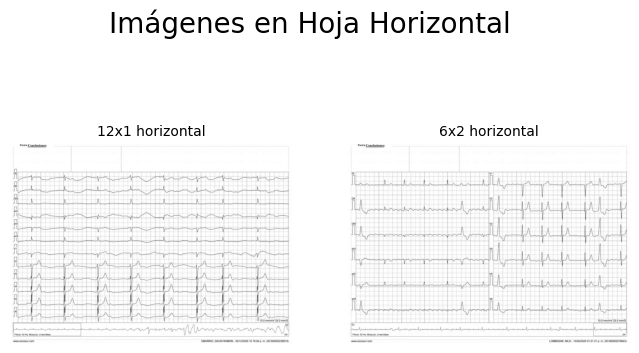

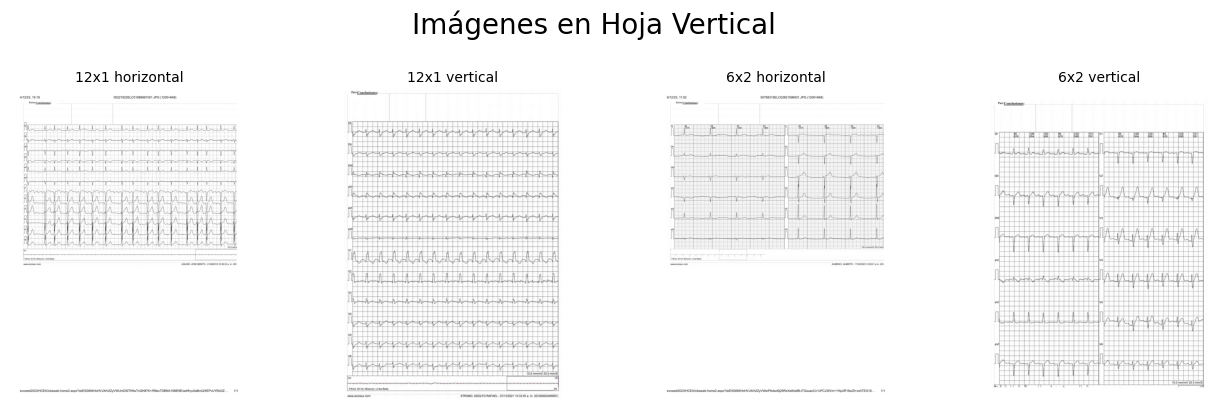

In [4]:
horizontal_path = os.path.join(examples_path, "Hoja Horizontal")
vertical_path = os.path.join(examples_path, "Hoja Vertical")


def load_images(folder):
    images = []
    names = []

    files = [f for f in os.listdir(folder) if f.lower().endswith(".jpg")]
    files.sort()

    for file in files:
        path = os.path.join(folder, file)
        img = cv2.imread(path)
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        images.append(img)
        names.append(os.path.splitext(file)[0])
    return images, names


# Cargar imágenes
h_imgs, h_names = load_images(horizontal_path)
v_imgs, v_names = load_images(vertical_path)


def plot_images(images, names, title):
    n = len(images)

    plt.figure(figsize=(4*n, 4))

    for i in range(n):
        plt.subplot(1, n, i + 1)
        plt.imshow(images[i])
        plt.title(names[i], fontsize=10)
        plt.axis("off")

    plt.suptitle(title, fontsize=20, y=1.08)
    plt.show()


# Horizontal
plot_images(h_imgs, h_names, "Imágenes en Hoja Horizontal")
# Vertical
plot_images(v_imgs, v_names, "Imágenes en Hoja Vertical")

Por otro lado, en los datos provistos se identificó también un subconjunto pequeño de imágenes que no corresponden a reportes digitales estandarizados, sino a escaneos o fotografías de registros impresos en papel. Estas imágenes presentan una calidad significativamente inferior, con artefactos de adquisición, menor nitidez y degradación visual. Por este motivo, se decidió descartar por completo estas imágenes. A continuación, se muestran ejemplos representativos de este tipo de registros excluidos.

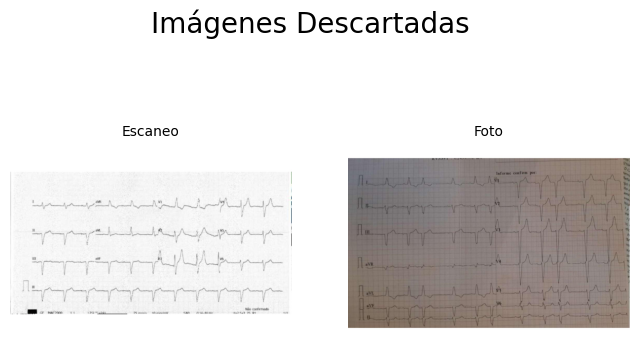

In [5]:
photos_path = os.path.join(examples_path, "Fotos")

p_imgs, p_names = load_images(photos_path)
plot_images(p_imgs, p_names, "Imágenes Descartadas")

In [6]:
# Contar imágenes por clase y layout
records = []

for class_name in classes:
    class_path = os.path.join(data_raw_path, class_name)
    if not os.path.isdir(class_path):
        continue

    for layout in layouts:
        layout_path = os.path.join(class_path, layout)

        count = 0
        if os.path.isdir(layout_path):
            count = sum(
                1 for f in os.listdir(layout_path)
                if f.lower().endswith(valid_ext)
            )

        records.append({
            "clase":    class_name,
            "layout":   layout,
            "cantidad": count,
        })

# Tabla resumen
df = pd.DataFrame(records)

pivot = df.pivot_table(
    index      = "layout",
    columns    = "clase",
    values     = "cantidad",
    fill_value = 0,
    aggfunc    = "sum"
)[list(classes.keys())]   # mantener orden de clases

pivot = pivot.reindex(layouts)   # mantener orden de layouts
pivot["TOTAL"] = pivot.sum(axis=1)
pivot.loc["TOTAL"] = pivot.sum()

print(pivot.to_string())

clase                               Am  HTA  EAo  MCH  TOTAL
layout                                                      
6x2 horizontal (hoja horizontal)    50   18  100  100    268
6x2 horizontal (hoja vertical)     136  160   92   30    418
6x2 vertical (hoja vertical)        36   11    0    5     52
12x1 horizontal (hoja horizontal)   12    1    0    0     13
12x1 horizontal (hoja vertical)     24    8    5    5     42
12x1 vertical (hoja vertical)        6    1    0    3     10
raras                               18    0    0    0     18
TOTAL                              282  199  197  143    821


No todas las clases presentan la misma variedad de layouts, y algunas configuraciones se encuentran en cantidades muy limitadas o incluso ausentes en determinadas patologías. Esto puede representar un problema, ya que podría inducir sesgos en la clasificación al asociar ciertas características del layout con clases específicas en lugar de con el contenido clínico del electrocardiograma.
Dada la escasa cantidad de datos en ciertos subgrupos y la falta de consistencia en la disponibilidad de todos los formatos de representación del electrocardiograma entre clases, se decidió restringir el análisis únicamente a las imágenes correspondientes al layout 6×2 horizontal, independientemente de si fueron exportadas en formato de hoja horizontal o vertical. La diferencia entre hoja horizontal y hoja vertical no implica un cambio en el contenido clínico del ECG ni en la disposición de las derivaciones, sino únicamente en los márgenes blancos del documento exportado. 

De este modo, la cantidad de imagenes inicial con la que se trabajará es de 668.

In [7]:
layouts_6x2h = [
    "6x2 horizontal (hoja horizontal)",
    "6x2 horizontal (hoja vertical)",
]

pivot_6x2h = pivot.loc[layouts_6x2h]
pivot_6x2h.loc["TOTAL"] = pivot_6x2h.sum()

print(pivot_6x2h.to_string())

clase                              Am  HTA  EAo  MCH  TOTAL
layout                                                     
6x2 horizontal (hoja horizontal)   50   18  100  100    268
6x2 horizontal (hoja vertical)    136  160   92   30    418
TOTAL                             186  178  192  130    686


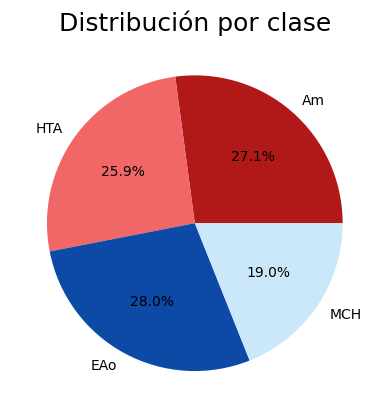

In [8]:
totals_6x2h = pivot_6x2h.loc["TOTAL", list(classes.keys())]

labels = list(totals_6x2h.index)
sizes  = list(totals_6x2h.values)
colors = [colors_map[label] for label in labels]

plt.figure()
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%')
plt.title("Distribución por clase", fontsize=18)
plt.show()

Arriba se observa en un grafico de torta la cantidad de imágenes correspondientes a cada clase, con el objetivo de evaluar la distribución de los datos y detectar posibles desbalances.

## **Unificación de Formato y Anonimización**

En primer lugar en el proceso de limpieza de datos, se analizó cuales son los diferentes formatos de archivo presentes en el dataset.

In [9]:
file_formats = Counter()
all_files = []

for class_name in classes:
    class_path = os.path.join(data_raw_path, class_name)
    if not os.path.isdir(class_path):
        continue

    for layout in layouts_6x2h:
        layout_path = os.path.join(class_path, layout)
        if not os.path.isdir(layout_path):
            continue

        for file in os.listdir(layout_path):
            file_ext = os.path.splitext(file)[1].lower()
            if file_ext in valid_ext:
                file_formats[file_ext] += 1
                all_files.append({
                    "class":     class_name,
                    "layout":    layout,
                    "filename":  file,
                    "extension": file_ext,
                })

files_df = pd.DataFrame(all_files)

print("📊 Formatos de imagen:\n")
total_files = sum(file_formats.values())
for ext, count in sorted(file_formats.items(), key=lambda x: x[1], reverse=True):
    print(f"• {ext.upper():<6} → {count:5d} imágenes ({count/total_files*100:.1f}%)")
print(f"\nTOTAL: {total_files} imágenes")

📊 Formatos de imagen:

• .PDF   →   493 imágenes (71.9%)
• .JPG   →   191 imágenes (27.8%)
• .JPEG  →     2 imágenes (0.3%)

TOTAL: 686 imágenes


Dado que el dataset posee imágenes en diferentes formatos (JPG, JPEG y PDF), resulta necesario unificar su representación para permitir un procesamiento homogéneo. En particular, tanto los archivos en formato PDF como los JPEG fueron convertidos a imágenes JPG, el formato mayoritario. Para esta conversión se utilizó una resolución de 200 DPI. La justificación detallada de la elección de este valor se presenta en el Anexo.

Por otro lado, con el objetivo de garantizar la privacidad de la información y eliminar cualquier posible identificador asociado a los pacientes, se realizó también un proceso de anonimización del dataset. Este consistió en el renombrado sistemático de los archivos, eliminando los nombres originales y reemplazándolos por identificadores numéricos consistentes dentro de cada clase. Cada imagen fue renombrada utilizando el formato Clase_N, donde Clase corresponde a la patología asociada (Am, EAo, HTA, MCH) y N es un índice incremental único dentro de cada categoría.



In [ ]:
dpi = 200

os.makedirs(data_filtered_path, exist_ok=True)

total_copied = 0

for class_name in classes:
    class_input  = os.path.join(data_raw_path, class_name)
    class_output = os.path.join(data_filtered_path, class_name)

    if not os.path.isdir(class_input):
        print(f"⚠️ No existe: {class_input}")
        continue

    os.makedirs(class_output, exist_ok=True)

    # Recolectar todos los archivos de los layouts 6x2 horizontal
    files = []
    for layout in layouts_6x2h:
        layout_path = os.path.join(class_input, layout)
        if not os.path.isdir(layout_path):
            continue
        for file in os.listdir(layout_path):
            ext = os.path.splitext(file)[1].lower()
            if ext in (".jpg", ".jpeg", ".pdf"):
                files.append(os.path.join(layout_path, file))

    files.sort()

    counter = 1
    for file_path in files:
        ext  = os.path.splitext(file_path)[1].lower()
        dst  = os.path.join(class_output, f"{class_name}_{counter}.jpg") # Renombrar archivo

        try:
            if ext == ".pdf":
                images = convert_from_path(file_path, dpi=dpi)
                for img in images:
                    img.save(dst, "JPEG")
                    total_copied += 1
                    counter += 1
                    dst = os.path.join(class_output, f"{class_name}_{counter}.jpg")

            elif ext in (".jpg", ".jpeg"):
                img = cv2.imdecode(np.fromfile(file_path, dtype=np.uint8), cv2.IMREAD_COLOR)
                if img is None:
                    print(f"❌ Error leyendo: {file_path}")
                    continue
                cv2.imwrite(dst, img)
                total_copied += 1
                counter += 1

        except Exception as e:
            print(f"❌ Error procesando {file_path}: {e}")

    print(f"  {class_name}: {counter - 1} imágenes")

print(f"\nTOTAL copiadas: {total_copied}")

Por último, se verifica que la totalidad de los archivos se haya convertido correctamente a JPG.

In [12]:
file_formats = Counter()
all_files = []

for class_name in os.listdir(data_filtered_path):
    if class_name not in classes:
        continue
    class_path = os.path.join(data_filtered_path, class_name)

    if not os.path.isdir(class_path):
        continue

    for root, dirs, files in os.walk(class_path):
        for file in files:
            file_ext = os.path.splitext(file)[1].lower()

            file_formats[file_ext] += 1

            all_files.append({
                "class": class_name,
                "filename": file,
                "extension": file_ext
            })

files_df = pd.DataFrame(all_files)

print("\n📊 Formatos de imagen:\n")

total_files = sum(file_formats.values())

for ext, count in sorted(file_formats.items(), key=lambda x: x[1], reverse=True):
    percentage = (count / total_files) * 100
    print(f"• {ext.upper():<6} → {count:5d} imágenes ({percentage:.2f}%)")

print(f"\nTOTAL: {total_files} imágenes")


📊 Formatos de imagen:

• .JPG   →   686 imágenes (100.00%)

TOTAL: 686 imágenes


## **Checkeo de Imágenes Duplicadas**

Como segundo paso del análisis del dataset, se verificó la posible presencia de imágenes duplicadas, ya que esto puede producir sesgos en el entrenamiento o provocar filtraciones de información entre los conjuntos de entrenamiento y evaluación.

Para detectar duplicados, se utilizó una técnica basada en funciones hash criptográficas (MD5). Un hash es una representación única de un archivo generada a partir de su contenido binario. De esta forma, dos imágenes idénticas producirán el mismo valor de hash, independientemente de su nombre o ubicación en el sistema de archivos.

In [20]:
def get_file_hash(filepath):
    with open(filepath, "rb") as f:
        file_hash = hashlib.md5()
        while chunk := f.read(8192):
            file_hash.update(chunk)
    return file_hash.hexdigest()

In [21]:
hash_dict = defaultdict(list)

# Recorrer dataset
for class_key in classes.keys():
    class_path = os.path.join(data_filtered_path, class_key)

    if not os.path.exists(class_path):
        continue

    for root, dirs, files in os.walk(class_path):

        for file in files:
            if file.lower().endswith(valid_ext):

                file_path = os.path.join(root, file)
                file_hash = get_file_hash(file_path)

                hash_dict[file_hash].append({
                    "path": file_path,
                    "class": class_key,
                    "filename": file
                })


# Detectar duplicados
duplicates = {h: files for h, files in hash_dict.items() if len(files) > 1}

print(f"📊 Imágenes duplicadas encontradas: {len(duplicates)}\n")

for file_hash, files in duplicates.items():
    print(f"Hash: {file_hash}")
    for f in files:
        print(f"  [{f['class']}] {f['filename']}  →  {f['path']}")
    print()

📊 Imágenes duplicadas encontradas: 0



No se encontraron imágenes duplicadas.

## **Análisis de Dimensiones**

Finalmente, también se analizó el tamaño en píxeles de las imágenes con el objetivo de evaluar la homogeneidad de los datos y definir las estrategias de preprocesamiento necesarias para el entrenamiento de los modelos.

In [11]:
size_data = []

for clase in classes.keys():
    folder_path = os.path.join(data_filtered_path, clase)
    
    if not os.path.exists(folder_path):
        print(f"No existe: {folder_path}")
        continue
    
    for root, dirs, files in os.walk(folder_path):
        for file in files:
            if file.lower().endswith(valid_ext):
                img_path = os.path.join(root, file)
                
                img = cv2.imread(img_path)
                
                if img is None:
                    print(f"❌ Error leyendo: {img_path}")
                    continue
                
                h, w = img.shape[:2]
                
                size_data.append({
                    "class": clase,
                    "width": w,
                    "height": h
                })

# Crear DataFrame
image_size_df = pd.DataFrame(size_data)

# Contar tamaños
size_counts = (
    image_size_df
    .groupby(["width", "height"])
    .size()
    .reset_index(name="count")
    .sort_values(by="count", ascending=False)
)

print("\n📊 Tamaños de imagen:\n")
print(size_counts.to_string(index=False))

print(f"\nTOTAL: {len(image_size_df)} imágenes")


📊 Tamaños de imagen:

 width  height  count
  1653    2339    290
  2339    1653    242
  1700    2200    115
  1200     848     15
  1654    2339     12
  2200    1700     12

TOTAL: 686 imágenes


La gran mayoría de los tamaños identificados corresponden a dos resoluciones principales (2339×1653 y 1653×2339 píxeles), las cuales representan la misma dimensión base con variaciones en la orientación de la hoja de exportación (formato vertical u horizontal de hoja A4). De manera similar, se observa un grupo con resolución 2200×1700 píxeles que presenta el mismo comportamiento, asociado a cambios en la orientación del documento en formato hoja carta. Es importante destacar que estas diferencias no implican una transformación del contenido del electrocardiograma, sino variaciones en cómo este se distribuye dentro del área total de la hoja. En particular, cuando el ECG es exportado en formato horizontal se ajusta de manera que ocupa una mayor proporción del ancho disponible de la hoja. En cambio, en el formato vertical, el contenido se mantiene con la misma orientación, pero queda contenido dentro de una hoja más alta, lo que genera márgenes blancos superiores e inferiores más amplios.

Adicionalmente, se identifica un conjunto minoritario con resolución 1200×848 píxeles, el cual, a pesar de su menor tamaño, mantiene una relación de aspecto consistente con las imágenes del grupo correspondiente a hoja A4. Este grupo probablemente corresponde a una configuración de exportación con menor resolución o a un flujo alternativo de generación de los archivos.

En conjunto, estos resultados indican que la variabilidad observada en las dimensiones no responde a cambios en la estructura del electrocardiograma, sino a diferencias en el formato de exportación del documento y en la distribución espacial del contenido dentro de la hoja. Esto es coherente con el hecho de que las imágenes provienen de un mismo sistema de adquisición, donde el ECG mantiene su estructura interna invariante independientemente del formato de salida.

------------------------------------------------------------------------------

-----------------------------------------
# **ANEXO**

## **Estimación de la Resolución Espacial**

Dado que el dataset posee imágenes en diferentes formatos (JPG y PDF), resulta necesario unificar su representación para permitir un procesamiento homogéneo. En particular, la conversión de los archivos PDF a imágenes requiere definir un valor de resolución adecuado, de modo que el tamaño final en píxeles sea consistente con el de las otras imágenes en formato JPG y además se preserve la escala espacial del electrocardiograma.

Las imágenes de ECG contienen una grilla estándar en la cual cada cuadrado grande corresponde a 5 mm. Esta propiedad permite establecer una relación directa entre la distancia en píxeles y la dimensión física real. En base a esto, se aplicaron técnicas de procesamiento de imágenes para detectar las líneas de la grilla (detección de bordes con Canny y transformada de Hough) y calcular la distancia entre líneas consecutivas.

In [137]:
img_path = r"C:\Users\Victoria\Desktop\Datos ICBA\Am\6x2 horizontal (hoja horizontal)\ECG 0.jpg"

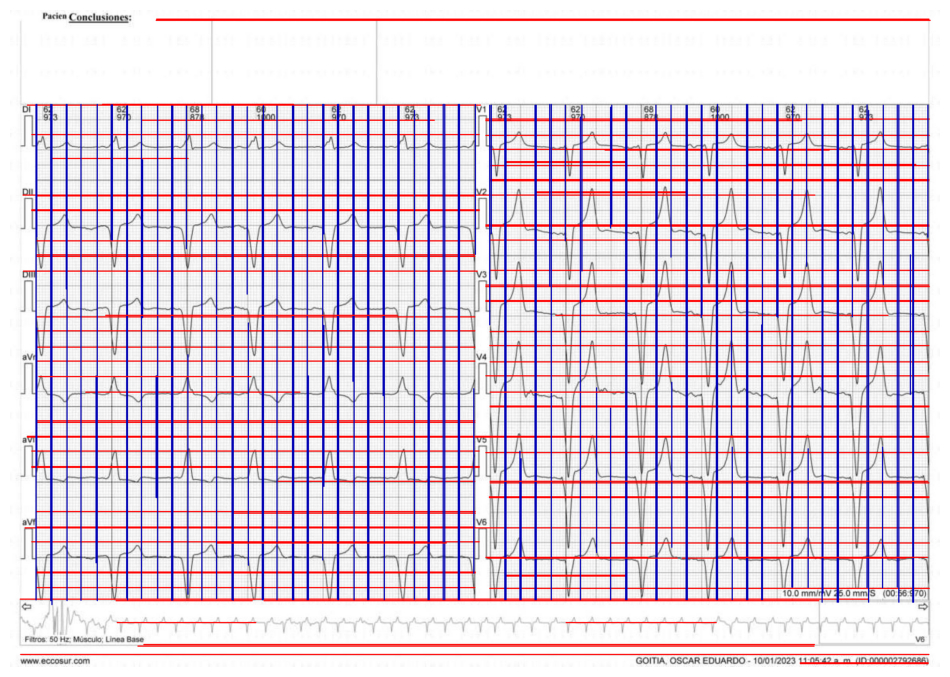

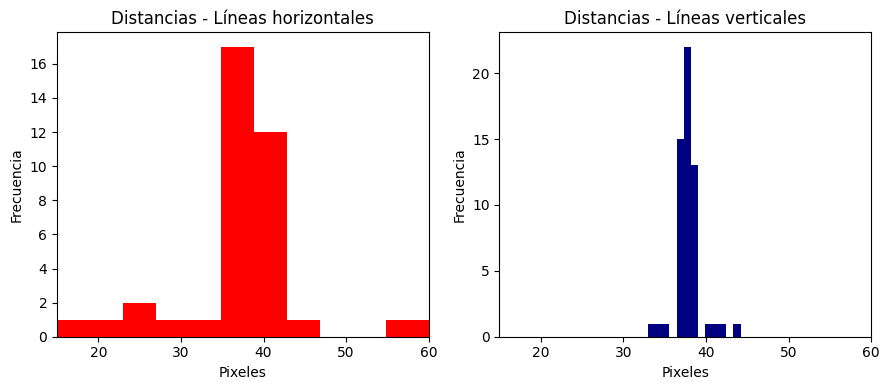

Distancia promedio: 39.79381443298969 px


In [138]:
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_lines = img.copy()

# Detección de líneas
edges = cv2.Canny(img, 50, 150)
lines = cv2.HoughLinesP(edges, 1, np.pi/180, threshold=80, minLineLength=300, maxLineGap=10)

ys = []
xs = []

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line[0]
        
        # Horizontales (rojo)
        if abs(y1 - y2) < 5:       
            ys.append(y1)
            cv2.line(img_lines, (x1, y1), (x2, y2), (255, 0, 0), 2)
        
        # Verticales (azul)
        elif abs(x1 - x2) < 5:   
            xs.append(x1)
            cv2.line(img_lines, (x1, y1), (x2, y2), (0, 0, 180), 2)

# Limpiar líneas duplicadas
def limpiar_coords(coords, tol=10):
    coords = sorted(coords)
    clean = []
    for c in coords:
        if not clean or abs(c - clean[-1]) > tol:
            clean.append(c)
    return clean

ys_clean = limpiar_coords(ys)
xs_clean = limpiar_coords(xs)

# Calcular distancia entre líneas
dist_y = np.diff(ys_clean)
dist_x = np.diff(xs_clean)
distancias = np.concatenate([dist_y, dist_x])



# Imagen con líneas
plt.figure(figsize=(12,10))
plt.imshow(img_lines)
plt.axis("off")
plt.show()

# Histogramas de Distancias
fig, axes = plt.subplots(1, 2, figsize=(9,4))
# Horizontales
axes[0].hist(dist_y, bins=50, color='red')
axes[0].set_title("Distancias - Líneas horizontales")
axes[0].set_xlabel("Pixeles")
axes[0].set_ylabel("Frecuencia")
axes[0].set_xlim(15, 60)
# Verticales
axes[1].hist(dist_x, bins=50, color='navy')
axes[1].set_title("Distancias - Líneas verticales")
axes[1].set_xlabel("Pixeles")
axes[1].set_ylabel("Frecuencia")
axes[1].set_xlim(15, 60)

plt.tight_layout()
plt.show()

# Distancia promedio
print("Distancia promedio:", np.mean(distancias), "px")

El análisis arrojó una distancia promedio de aproximadamente 40 píxeles. Para verificar que este valor sea representativo, se realizó una inspección visual mediante la superposición sobre la imagen original de aquellas líneas cuya separación corresponde aproximadamente a dicha distancia.

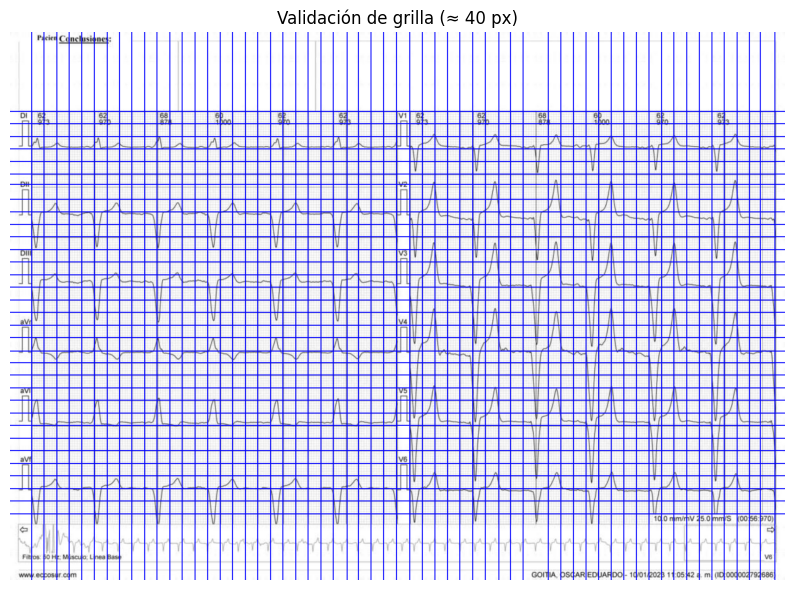

In [81]:
img_lines_val = img.copy()

target = 40
tolerancia = 6

# Horizontales
for i in range(len(ys_clean) - 1):
    d = ys_clean[i+1] - ys_clean[i]

    if abs(d - target) < tolerancia:
        y1 = ys_clean[i]
        y2 = ys_clean[i+1]

        cv2.line(img_lines_val, (0, y1), (img.shape[1], y1), (0, 0, 255), 2)
        cv2.line(img_lines_val, (0, y2), (img.shape[1], y2), (0, 0, 255), 2)

# Verticales
for i in range(len(xs_clean) - 1):
    d = xs_clean[i+1] - xs_clean[i]

    if abs(d - target) < tolerancia:
        x1 = xs_clean[i]
        x2 = xs_clean[i+1]

        cv2.line(img_lines_val, (x1, 0), (x1, img.shape[0]), (0, 0, 255), 2)
        cv2.line(img_lines_val, (x2, 0), (x2, img.shape[0]), (0, 0, 255), 2)

# Mostrar
plt.figure(figsize=(10,8))
plt.imshow(img_lines_val)
plt.title("Validación de grilla (≈ 40 px)")
plt.axis("off")
plt.show()

La distribución regular y equiespaciada observada confirma que estas líneas coinciden con la grilla del electrocardiograma. Por lo tanto, a partir de este valor promedio de distancia medido se calculó la resolución en DPI mediante la siguiente expresión:
$$
DPI = \frac{d_{px} \cdot 25.4}{5}
$$

En base a esto, se concluye que las imágenes del dataset presentan una resolución aproximada de 200 DPI. Por lo tanto, se adopta este valor como referencia para la conversión de archivos PDF a formato JPG.